In [62]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

heart = pd.read_csv("Heart_dataset.csv")
heart

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145.0,233,1.0,2.0,150.0,0.0,2.3,3.0,0.0,fixed,No
1,2,67,1,asymptomatic,160.0,286,0.0,2.0,108.0,1.0,1.5,2.0,3.0,normal,Yes
2,3,67,1,asymptomatic,120.0,229,0.0,2.0,129.0,1.0,2.6,2.0,2.0,reversable,Yes
3,4,37,1,nonanginal,130.0,250,0.0,0.0,187.0,0.0,3.5,3.0,0.0,normal,No
4,5,41,0,nontypical,130.0,204,0.0,2.0,172.0,0.0,1.4,1.0,0.0,normal,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,299,45,1,typical,110.0,264,0.0,0.0,132.0,0.0,1.2,2.0,0.0,reversable,Yes
299,300,68,1,asymptomatic,144.0,193,1.0,0.0,141.0,0.0,3.4,2.0,2.0,reversable,Yes
300,301,57,1,asymptomatic,130.0,131,0.0,0.0,115.0,1.0,1.2,2.0,1.0,reversable,Yes
301,302,57,0,nontypical,130.0,236,0.0,2.0,174.0,0.0,0.0,2.0,1.0,normal,Yes


In [63]:
heart = heart.drop(columns=["Unnamed: 0"])

In [64]:
heart

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,typical,145.0,233,1.0,2.0,150.0,0.0,2.3,3.0,0.0,fixed,No
1,67,1,asymptomatic,160.0,286,0.0,2.0,108.0,1.0,1.5,2.0,3.0,normal,Yes
2,67,1,asymptomatic,120.0,229,0.0,2.0,129.0,1.0,2.6,2.0,2.0,reversable,Yes
3,37,1,nonanginal,130.0,250,0.0,0.0,187.0,0.0,3.5,3.0,0.0,normal,No
4,41,0,nontypical,130.0,204,0.0,2.0,172.0,0.0,1.4,1.0,0.0,normal,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,typical,110.0,264,0.0,0.0,132.0,0.0,1.2,2.0,0.0,reversable,Yes
299,68,1,asymptomatic,144.0,193,1.0,0.0,141.0,0.0,3.4,2.0,2.0,reversable,Yes
300,57,1,asymptomatic,130.0,131,0.0,0.0,115.0,1.0,1.2,2.0,1.0,reversable,Yes
301,57,0,nontypical,130.0,236,0.0,2.0,174.0,0.0,0.0,2.0,1.0,normal,Yes


In [65]:
heart.shape

(303, 14)

In [67]:
heart.mean(numeric_only=True)

Age         54.438944
Sex          0.679868
RestBP     131.662252
Chol       246.693069
Fbs          0.149007
RestECG      0.986755
MaxHR      149.674419
ExAng        0.324503
Oldpeak      1.039604
Slope        1.602649
Ca           0.672241
dtype: float64

In [68]:
heart.mode(numeric_only=True)

,Age,Sex,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca
0,58.0,1.0,120.0,197,0.0,0.0,162.0,0.0,0.0,1.0,0.0
1,NaN,NaN,NaN,204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,234,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [69]:
heart.median(numeric_only=True)

Age         56.0
Sex          1.0
RestBP     130.0
Chol       241.0
Fbs          0.0
RestECG      0.5
MaxHR      153.0
ExAng        0.0
Oldpeak      0.8
Slope        2.0
Ca           0.0
dtype: float64

In [70]:
heart.isnull().any()

Age          False
Sex          False
ChestPain    False
RestBP        True
Chol         False
Fbs           True
RestECG       True
MaxHR         True
ExAng         True
Oldpeak      False
Slope         True
Ca            True
Thal          True
AHD          False
dtype: bool

In [71]:
heart.isnull().sum()

Age          0
Sex          0
ChestPain    0
RestBP       1
Chol         0
Fbs          1
RestECG      1
MaxHR        2
ExAng        1
Oldpeak      0
Slope        1
Ca           4
Thal         2
AHD          0
dtype: int64

In [73]:
le = LabelEncoder()

cols = ['ChestPain', 'Thal' , 'AHD']

for col in cols:
    heart[col]=le.fit_transform(heart[col])

In [74]:
heart

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,3,145.0,233,1.0,2.0,150.0,0.0,2.3,3.0,0.0,0,0
1,67,1,0,160.0,286,0.0,2.0,108.0,1.0,1.5,2.0,3.0,1,1
2,67,1,0,120.0,229,0.0,2.0,129.0,1.0,2.6,2.0,2.0,2,1
3,37,1,1,130.0,250,0.0,0.0,187.0,0.0,3.5,3.0,0.0,1,0
4,41,0,2,130.0,204,0.0,2.0,172.0,0.0,1.4,1.0,0.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,3,110.0,264,0.0,0.0,132.0,0.0,1.2,2.0,0.0,2,1
299,68,1,0,144.0,193,1.0,0.0,141.0,0.0,3.4,2.0,2.0,2,1
300,57,1,0,130.0,131,0.0,0.0,115.0,1.0,1.2,2.0,1.0,2,1
301,57,0,2,130.0,236,0.0,2.0,174.0,0.0,0.0,2.0,1.0,1,1


In [75]:
heart["RestBP"] = heart["RestBP"].fillna(heart.RestBP.mean())

In [77]:
heart["Fbs"] = heart["Fbs"].fillna(heart.Fbs.median())

In [78]:
heart["RestECG"] = heart["RestECG"].fillna(heart.RestECG.median())

In [79]:
heart["MaxHR"] = heart["MaxHR"].fillna(heart.MaxHR.median())

In [80]:
heart["ExAng"] = heart["ExAng"].fillna(heart.ExAng.median())

In [81]:
heart["Slope"] = heart["Slope"].fillna(heart.Slope.median())

In [82]:
heart["Ca"] = heart["Ca"].fillna(heart.Ca.median())

In [83]:
heart["Thal"] = heart["Thal"].fillna(heart.Thal.median())

In [84]:
heart.isnull().sum()

Age          0
Sex          0
ChestPain    0
RestBP       0
Chol         0
Fbs          0
RestECG      0
MaxHR        0
ExAng        0
Oldpeak      0
Slope        0
Ca           0
Thal         0
AHD          0
dtype: int64

In [85]:
heart

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,3,145.0,233,1.0,2.0,150.0,0.0,2.3,3.0,0.0,0,0
1,67,1,0,160.0,286,0.0,2.0,108.0,1.0,1.5,2.0,3.0,1,1
2,67,1,0,120.0,229,0.0,2.0,129.0,1.0,2.6,2.0,2.0,2,1
3,37,1,1,130.0,250,0.0,0.0,187.0,0.0,3.5,3.0,0.0,1,0
4,41,0,2,130.0,204,0.0,2.0,172.0,0.0,1.4,1.0,0.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,3,110.0,264,0.0,0.0,132.0,0.0,1.2,2.0,0.0,2,1
299,68,1,0,144.0,193,1.0,0.0,141.0,0.0,3.4,2.0,2.0,2,1
300,57,1,0,130.0,131,0.0,0.0,115.0,1.0,1.2,2.0,1.0,2,1
301,57,0,2,130.0,236,0.0,2.0,174.0,0.0,0.0,2.0,1.0,1,1


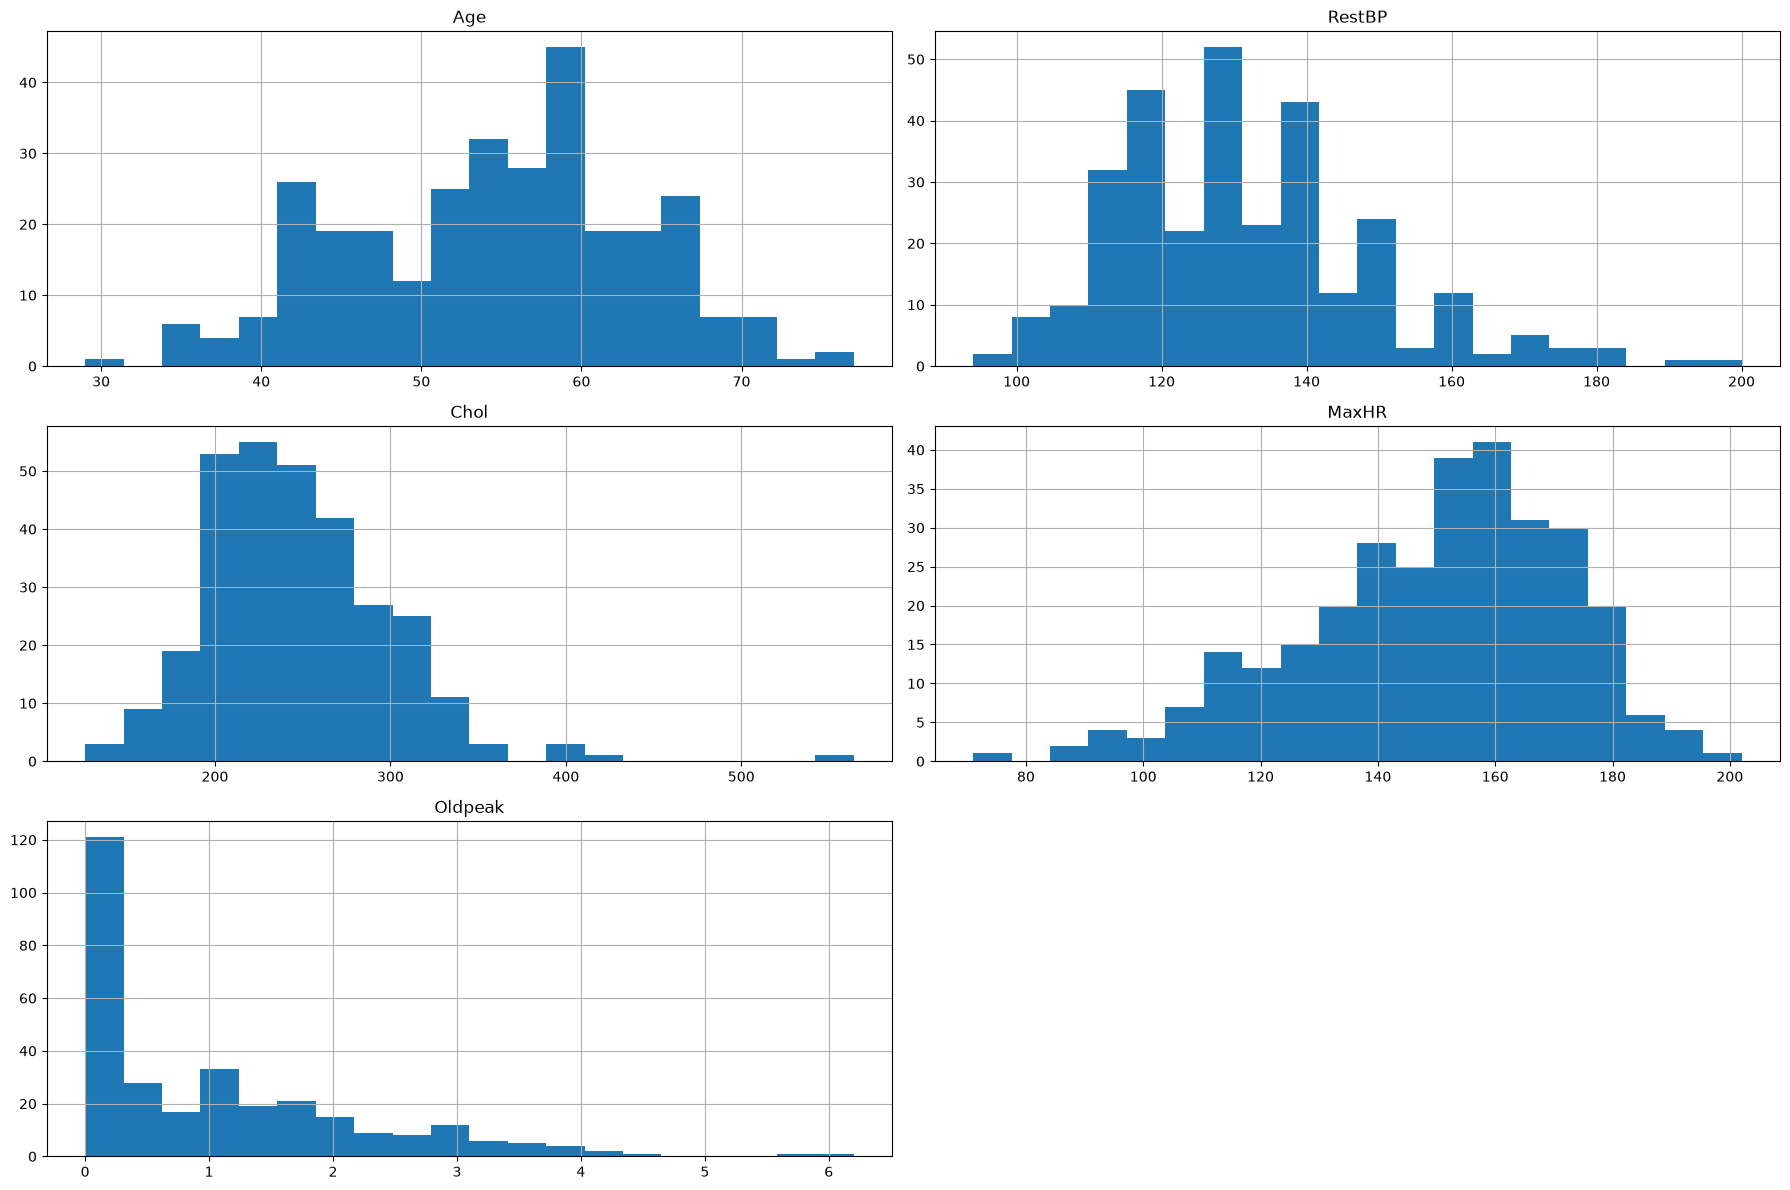

In [86]:
heart[["Age", "RestBP", "Chol", "MaxHR", "Oldpeak"]].hist(figsize=(18, 12), bins=20)
plt.tight_layout()

<function matplotlib.pyplot.plot(*args: 'float | ArrayLike | str', scalex: 'bool' = True, scaley: 'bool' = True, data: 'DataParamType' = None, **kwargs) -> 'list[Line2D]'>

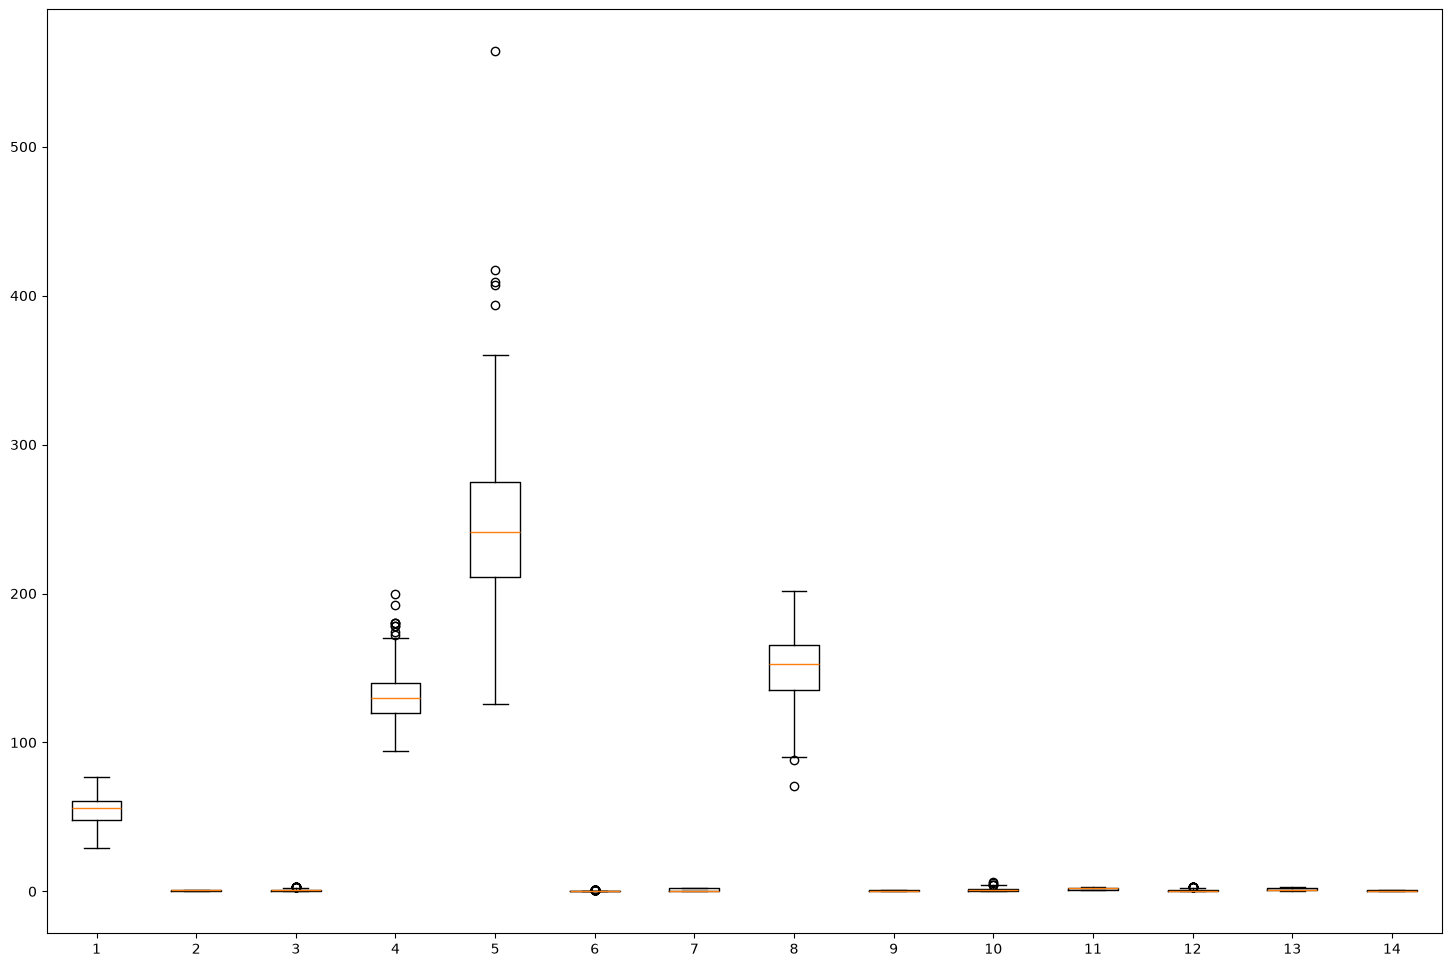

In [87]:
fig, ax = plt.subplots(figsize=(18, 12))
box = ax.boxplot(heart)
plt.plot

In [90]:
x = heart.drop(columns=['AHD'])
y = heart['AHD']

x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=42)

continuous_cols = ['Age', 'RestBP', 'Chol', 'MaxHR', 'Oldpeak']

min_max_scaler = MinMaxScaler()

x_train[continuous_cols] = min_max_scaler.fit_transform(x_train[continuous_cols])
x_test[continuous_cols] = min_max_scaler.transform(x_test[continuous_cols])


x_train

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal
132,0.000000,1,2,0.339623,0.268041,0.0,2.0,1.000000,0.0,0.000000,1.0,0.0,1
202,0.583333,1,1,0.528302,0.000000,1.0,0.0,0.778626,0.0,0.032258,1.0,1.0,2
196,0.833333,1,3,0.622642,0.371134,1.0,2.0,0.458015,0.0,0.016129,2.0,1.0,1
75,0.750000,0,1,0.622642,0.804124,0.0,2.0,0.610687,0.0,0.129032,1.0,0.0,1
176,0.479167,1,0,0.132075,0.367698,1.0,0.0,0.580153,0.0,0.016129,1.0,3.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
188,0.520833,1,2,0.924528,0.539519,0.0,2.0,0.946565,0.0,0.000000,1.0,1.0,2
71,0.791667,1,0,0.292453,0.439863,1.0,0.0,0.702290,0.0,0.032258,2.0,2.0,2
106,0.625000,1,0,0.433962,0.175258,0.0,0.0,0.694656,1.0,0.000000,1.0,1.0,2
270,0.666667,1,0,0.433962,0.278351,0.0,2.0,0.511450,1.0,0.306452,1.0,1.0,2


In [91]:
x_test

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal
179,0.500000,1,1,0.339623,0.412371,1.0,2.0,0.778626,0.0,0.000000,1.0,3.0,1
228,0.520833,1,0,0.150943,0.274914,0.0,2.0,0.282443,1.0,0.000000,2.0,1.0,1
111,0.562500,1,0,0.292453,0.422680,1.0,2.0,0.557252,1.0,0.193548,2.0,1.0,1
246,0.604167,1,0,0.056604,0.371134,0.0,0.0,0.648855,0.0,0.016129,1.0,1.0,2
60,0.458333,0,0,0.339623,0.615120,0.0,0.0,0.541985,1.0,0.193548,2.0,0.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,0.687500,1,2,0.320755,0.281787,1.0,2.0,0.526718,0.0,0.000000,1.0,0.0,1
104,0.416667,1,1,0.245283,0.213058,0.0,0.0,0.519084,0.0,0.322581,2.0,3.0,2
300,0.583333,1,0,0.339623,0.017182,0.0,0.0,0.335878,1.0,0.193548,2.0,1.0,2
193,0.687500,0,0,0.415094,0.577320,1.0,0.0,0.267176,0.0,0.306452,2.0,3.0,1
